# Public checkpoint: selected-time denoising profile

Run the single code cell in a **fresh project .venv (Python 3.12.11) kernel**.
The Windows ROOT is set at the top. No variables from another notebook are needed.

This extends the previous paired probe while preserving its checkpoint, pinned
sources, 16 configurations per endpoint, dequantization, and seed rules.
The selected indices are **0, 10, 25, 50, 75, 90, 95, 97, 98, 99**.
Both endpoints use temperature control 5. For each time and endpoint, compare
forward-noised auxiliary channels against auxiliary channels clamped to 5 and p,
holding coordinate inputs and model RNG states identical within each pair.

There are **40 reverse-kernel calls** (possibly extra self-conditioning forwards),
no optimizer updates and no complete reverse sampling. The original model and
source files are not edited. Each execution creates a separate output directory.
The historical training recipe of the public checkpoint remains unknown.

The plot reports coordinate noise RMSE, coordinate x0 reconstruction RMSE, and
three-channel mean Smooth L1 on logarithmic axes. JSON also records all three
channel losses and per-configuration coordinate errors. The constant endpoint-mean
baseline uses the full input data mean; it is a diagnostic baseline, not a learned
generative model. No claim of independent lattice sites or confidence intervals
is made. Only the listed times are evaluated; lines between them are guides.

Interpretation: noise and x0 errors obey the same algebraic relation and are not
independent evidence. This is supervised prediction on real forward-noised data,
not an evaluation of complete reverse-chain accuracy. Losses here are not the
historical training loss, nor an estimate averaged uniformly over all 100 times.
Clamping changes both auxiliary channels simultaneously. It tests local model
sensitivity and does not validate a replacement sampler.

Checks cover sources/checkpoint, forward inversion, paired coordinates/RNG,
error identities, native versus recomputed Smooth L1, and unchanged model state.
As t=98 and 99 retain the previous seeds and inputs, their results can also be
compared with the previous paired-probe ZIP. This comparison is not automated.

At completion upload **time_profile_results.zip**, whose exact location is printed.
It contains config, metrics, paired effects, checks, raw arrays, and the plot.
Prepared with syntax and saved-array metric checks; actual model execution is
performed in your local pinned PyTorch environment.


C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\author_source\GC_Lattice_gas\expTM_data_genenration\tm\core\backbone.py:126: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimen

p=-1, t=0, forward_noised_aux  | noise RMSE=2.444670 | x0 RMSE=0.0244 | x0 mean/std=-0.9073/0.4132
p=-1, t=0, clamped_aux         | noise RMSE=2.445428 | x0 RMSE=0.0245 | x0 mean/std=-0.9073/0.4132
p=-1, t=10, forward_noised_aux  | noise RMSE=1.522814 | x0 RMSE=0.1685 | x0 mean/std=-0.9286/0.3198
p=-1, t=10, clamped_aux         | noise RMSE=1.507150 | x0 RMSE=0.1668 | x0 mean/std=-0.9274/0.3128
p=-1, t=25, forward_noised_aux  | noise RMSE=1.151940 | x0 RMSE=0.3102 | x0 mean/std=-0.9408/0.2190
p=-1, t=25, clamped_aux         | noise RMSE=1.222327 | x0 RMSE=0.3291 | x0 mean/std=-0.9336/0.1962
p=-1, t=50, forward_noised_aux  | noise RMSE=0.718239 | x0 RMSE=0.4258 | x0 mean/std=-0.9313/0.2138
p=-1, t=50, clamped_aux         | noise RMSE=0.924293 | x0 RMSE=0.5480 | x0 mean/std=-0.9072/0.3268
p=-1, t=75, forward_noised_aux  | noise RMSE=0.446578 | x0 RMSE=0.5222 | x0 mean/std=-0.9300/0.3297
p=-1, t=75, clamped_aux         | noise RMSE=0.819180 | x0 RMSE=0.9579 | x0 mean/std=-0.8566/0.8103
p=

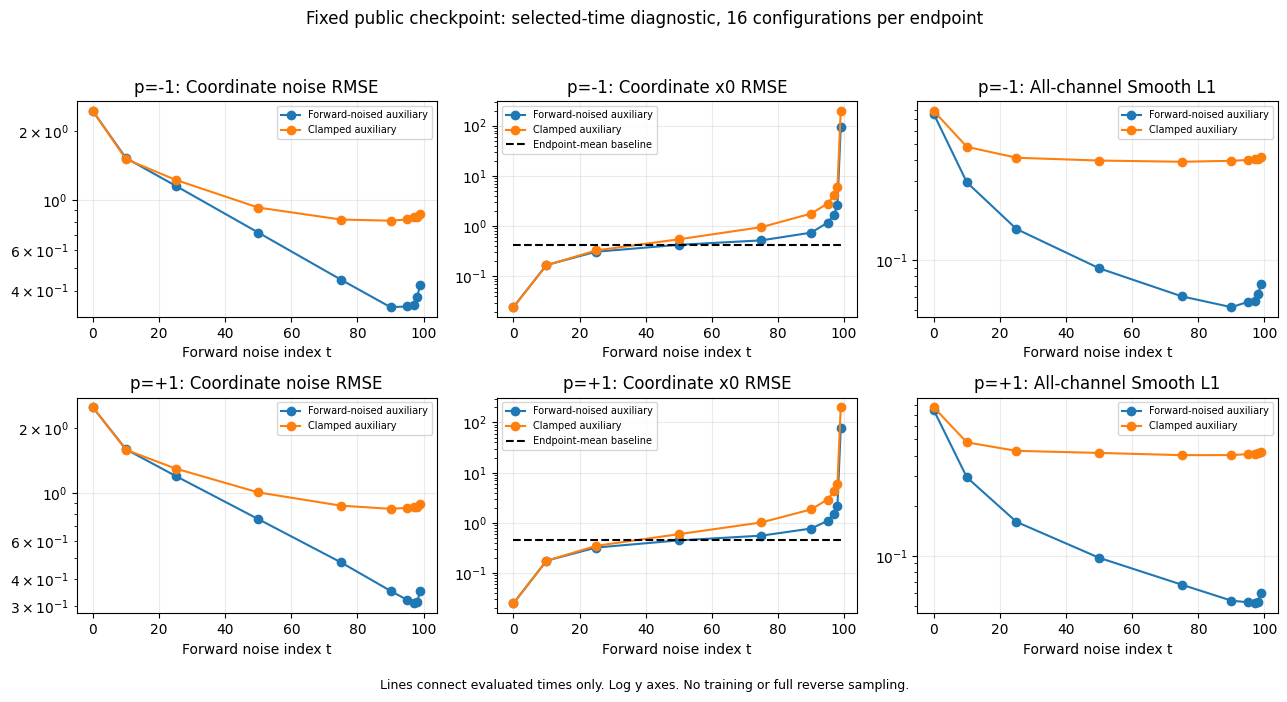


All pairing and arithmetic checks passed. No model updates were performed.
Upload this file: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\public_time_profile_20261101_020330_207107\time_profile_results.zip


In [1]:
from pathlib import Path
from datetime import datetime
import sys
import importlib
import hashlib
import json
import random
import platform
import numpy as np
import torch

ROOT = Path(r"C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1")
SOURCE = ROOT / "author_source" / "GC_Lattice_gas" / "expTM_data_genenration"
DATA = SOURCE.parent / "data"
CHECKPOINT = SOURCE / "thermomaps-root" / "models" / "model_1.pt"
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

assert Path(sys.executable).resolve() == (ROOT / ".venv" / "Scripts" / "python.exe").resolve(), (
    "Select the project's .venv kernel first."
)
assert str(torch.__version__) == "2.5.1+cpu", "Use the recorded PyTorch 2.5.1+cpu environment."
assert not torch.cuda.is_available(), "This comparison uses the recorded CPU protocol."
assert torch.get_default_dtype() == torch.float32
assert sha256(CHECKPOINT) == "72125a26b5d136b8eeda782ff01fbecb99963b3ad58b8fce3f4494185f5419fc"

expected = {
    "tm.core.loader": "3ca9e881b03ddbaea1bc1f0c61cdb61e4fa5a92bb347da0f944d84960b3b2e7a",
    "tm.core.prior": "674a7427efc278ae007cafda823dcb2ebab1fe2070455d33f5968bc54b680abb",
    "tm.core.diffusion_model": "849ecf96d9b2e476bffa65e31a56028db4ab82f2db45a89cfc4aa1c1135f6dce",
    "tm.core.diffusion_process": "fb4b3c55444d736cb4db3917d663b5a5bd16c27a9a3eaba408abe1a656ae434c",
    "tm.core.backbone": "e414f5a53c456c1ffb68d910cced0cd49627c2853fe7ff19d26ebd1e2eb040d2",
    "tm.core.utils": "d5e3f31598342c2aec6b673c786c996082602bd7ca8b645d8e47ac00163b6463",
    "tm.architectures.unet_2d_mid_attn": "87f662a0474f4beb53d125afc7222b11bb30c9f2840f3e273215f76b3bf8c63c",
}
for name, digest in expected.items():
    path = SOURCE.joinpath(*name.split('.')).with_suffix('.py')
    assert sha256(path) == digest, f"Source changed: {path}. Review before running."
sys.path.insert(0, str(SOURCE)) if str(SOURCE) not in sys.path else None
modules = {name: importlib.import_module(name) for name in expected}
for name, module in modules.items():
    wanted = SOURCE.joinpath(*name.split('.')).with_suffix('.py').resolve()
    assert Path(module.__file__).resolve() == wanted, (
        f"Wrong loaded module: {name}. Restart the kernel and run this notebook only."
    )

VPDiffusion = modules['tm.core.diffusion_process'].VPDiffusion
Prior = modules['tm.core.prior'].GlobalEquilibriumHarmonicPrior
Backbone = modules['tm.core.backbone'].ConvBackbone
Unet = modules['tm.architectures.unet_2d_mid_attn'].Unet2D

import zipfile
import matplotlib.pyplot as plt

Loader = modules['tm.core.loader'].Loader
N = 16
TIMESTEPS = [0, 10, 25, 50, 75, 90, 95, 97, 98, 99]
INDEX_SEED = 2026110101
DEQUANT_SEED = 2026110102
NOISE_SEED = 2026110103
MODEL_SEED = 2026110104

def as_numpy(tensor):
    return tensor.detach().cpu().numpy().copy()

def coord_metrics(x0hat, epshat, target, eps, alpha):
    # Compute coordinate metrics in float64; auxiliary targets are not scored.
    pred = np.asarray(x0hat[:, 0], dtype=np.float64)
    truth = np.asarray(target[:, 0], dtype=np.float64)
    noise_error = np.asarray(epshat[:, 0], dtype=np.float64) - np.asarray(eps[:, 0], dtype=np.float64)
    clean_error = pred - truth
    gain = np.sqrt((1-alpha)/alpha)
    return dict(
        noise_rmse=float(np.sqrt(np.mean(noise_error**2))),
        noise_bias=float(noise_error.mean()),
        x0_rmse=float(np.sqrt(np.mean(clean_error**2))),
        x0_bias=float(clean_error.mean()),
        x0_mean=float(pred.mean()), x0_std=float(pred.std()),
        x0_fraction_abs_gt_2=float(np.mean(np.abs(pred) > 2)),
        error_identity_max_abs=float(np.max(np.abs(clean_error + gain*noise_error))),
    )

def channel_metrics(epshat, eps):
    error = np.asarray(epshat, dtype=np.float64) - np.asarray(eps, dtype=np.float64)
    absolute = np.abs(error)
    huber = np.where(absolute < 1, 0.5 * error**2, absolute - 0.5)
    return dict(
        channel_order=['coordinate', 'temperature', 'pressure'],
        noise_rmse_by_channel=np.sqrt(np.mean(error**2, axis=(0, 2, 3))).tolist(),
        smooth_l1_by_channel=huber.mean(axis=(0, 2, 3)).tolist(),
        smooth_l1_all=float(huber.mean()),
        per_configuration_coordinate_noise_mse=np.mean(error[:, 0]**2, axis=(1, 2)).tolist(),
    )

def plot_profile(metrics, effects, out):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), squeeze=False)
    for row_index, p in enumerate([-1, 1]):
        for mode, label in [('forward_noised_aux', 'Forward-noised auxiliary'),
                            ('clamped_aux', 'Clamped auxiliary')]:
            rows = sorted([r for r in metrics if r['p'] == p and r['mode'] == mode], key=lambda r:r['t'])
            for j, key in enumerate(['noise_rmse', 'x0_rmse', 'smooth_l1_all']):
                axes[row_index, j].plot([r['t'] for r in rows], [r[key] for r in rows], 'o-', label=label)
        baseline = sorted([r for r in effects if r['p'] == p], key=lambda r:r['t'])
        axes[row_index, 1].plot([r['t'] for r in baseline],
            [r['constant_mean_baseline_x0_rmse'] for r in baseline], 'k--', label='Endpoint-mean baseline')
        for j, title in enumerate(['Coordinate noise RMSE', 'Coordinate x0 RMSE', 'All-channel Smooth L1']):
            ax = axes[row_index, j]
            ax.set(title=f'p={p:+d}: {title}', xlabel='Forward noise index t', yscale='log')
            ax.grid(alpha=.25)
            ax.legend(fontsize=7)
    fig.suptitle('Fixed public checkpoint: selected-time diagnostic, 16 configurations per endpoint')
    fig.text(.5, .01, 'Lines connect evaluated times only. Log y axes. No training or full reverse sampling.', ha='center', fontsize=9)
    fig.tight_layout(rect=(0, .035, 1, .95))
    fig.savefig(out/'time_profile.png', dpi=180)
    plt.show()
    plt.close(fig)

def run_time_profile():
    out = ROOT / 'outputs' / ('public_time_profile_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    out.mkdir(parents=True, exist_ok=False)
    config = dict(
        checkpoint=str(CHECKPOINT), checkpoint_sha256=sha256(CHECKPOINT),
        source_sha256=expected, python=platform.python_version(), torch=str(torch.__version__),
        numpy=np.__version__, samples_per_endpoint=N, timesteps=TIMESTEPS,
        temperature_control=5, pressure_controls=[-1, 1], device='cpu', threads=2,
        backbone_eval_mode='train', self_condition=True,
        index_seed=INDEX_SEED, dequant_seed=DEQUANT_SEED,
        noise_seed_base=NOISE_SEED, model_seed_base=MODEL_SEED,
        forward_noise_seed_rule='NOISE_SEED + t; same seed at both endpoints',
        model_seed_rule='MODEL_SEED + t; reset before each paired prediction',
        data_dequantization='Original Loader: normal, scale 0.01, once per selected batch',
        variants=['forward_noised_aux', 'clamped_aux'],
        scope='40 reverse_kernel calls; no reverse chain, optimization, or source changes',
        loss_definition='Smooth L1 beta=1, mean over sites, configurations, and 3 channels',
        timestep_scope='Selected times only; not a full 100-time sweep or a training-loss estimate',
        original_public_training_recipe_recovered=False,
        baseline='Constant x0 equal to full endpoint raw coordinate mean; diagnostic only',
        status='started',
    )
    (out/'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    dp = VPDiffusion(num_diffusion_timesteps=100)
    prior = Prior(shape=(N, 3, 20, 20), channels_info={'coordinate':[0], 'fluctuation':[1], 'mean':[2]})
    model = Unet(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
    bb = Backbone(model=model, data_shape=20, target_shape=32, num_dims=4,
                  lr=1e-3, eval_mode='train', self_condition=True)
    bb.load_model(str(CHECKPOINT.parent), 1, device='cpu')
    model_before = {k:v.detach().clone() for k,v in bb.model.state_dict().items()}
    metrics, effects, checks, records = [], [], [], {}
    for p, filename in [(-1, 'LowMuT7.npy'), (1, 'HighMuT7.npy')]:
        full = np.load(DATA/filename, mmap_mode='r', allow_pickle=False)
        assert full.shape[1:] == (2, 20, 20)
        assert np.all((full[:,0] == -1) | (full[:,0] == 1))
        # Explicitly chosen diagnostic batch, not a recovered author subset.
        indices = np.sort(np.random.default_rng(INDEX_SEED).choice(len(full), N, replace=False))
        raw = np.zeros((N, 3, 20, 20), dtype=np.float32)
        raw[:,0] = full[indices,0]
        raw[:,1] = 5
        raw[:,2] = p
        reference_mean = float(np.asarray(full[:,0], dtype=np.float64).mean())
        torch.manual_seed(DEQUANT_SEED)
        loader = Loader(data=raw.copy(), temperatures=np.full((N,1), 5.),
                        pressures=np.full((N,1), float(p)), control_dims=(1,3))
        x0 = torch.stack([loader[i][2] for i in range(N)])
        assert torch.equal(x0, loader.data.float())
        records[f'p{p:+d}_indices'] = indices
        records[f'p{p:+d}_raw'] = raw
        records[f'p{p:+d}_dequantized'] = as_numpy(x0)
        config.setdefault('data', []).append(dict(
            p=p, file=str(DATA/filename), sha256=sha256(DATA/filename),
            full_endpoint_mean=reference_mean, selected_indices=indices.tolist()))
        for step in TIMESTEPS:
            times = torch.full((N,), step, dtype=torch.long)
            alpha = float(dp.alphas[step])
            torch.manual_seed(NOISE_SEED + step)
            xt, eps = dp.forward_kernel(
                x0, times, prior, batch_size=N,
                temperatures=torch.full((N,1), 5.), pressures=torch.full((N,1), float(p)))
            xt_before, eps_before, x0_before = xt.clone(), eps.clone(), x0.clone()
            eps_np, x0_np, xt_np = as_numpy(eps), as_numpy(x0), as_numpy(xt)
            prefix=f'p{p:+d}_t{step}'
            records[prefix+'_xt'] = xt_np
            records[prefix+'_realized_noise'] = eps_np
            # Arithmetic check only: realized noise is NOT a deployable reverse predictor.
            reconstructed = (xt - np.sqrt(1-alpha)*eps)/np.sqrt(alpha)
            reconstruction_error = float((reconstructed-x0).abs().max())
            assert torch.allclose(reconstructed, x0, atol=5e-4, rtol=1e-4)
            variants, predictions, after_rng = {}, {}, []
            for mode in ['forward_noised_aux', 'clamped_aux']:
                inp=xt.clone()
                if mode == 'clamped_aux':
                    inp[:,1]=5
                    inp[:,2]=p
                assert torch.equal(inp[:,0], xt[:,0])
                # Equal random state also pairs the backbone's self-conditioning branch.
                random.seed(MODEL_SEED + step)
                np.random.seed(MODEL_SEED + step)
                torch.manual_seed(MODEL_SEED + step)
                with torch.no_grad():
                    clean_hat, noise_hat = dp.reverse_kernel(inp, times, bb, 'noise')
                after_rng.append(torch.get_rng_state().clone())
                clean_np, noise_np = as_numpy(clean_hat), as_numpy(noise_hat)
                assert np.isfinite(clean_np).all() and np.isfinite(noise_np).all()
                row = dict(p=p, t=step, mode=mode, alpha=alpha,
                           noise_error_gain=float(np.sqrt((1-alpha)/alpha)),
                           input_temperature_mean=float(inp[:,1].mean()),
                           input_temperature_std=float(inp[:,1].std(unbiased=False)),
                           input_pressure_mean=float(inp[:,2].mean()),
                           input_pressure_std=float(inp[:,2].std(unbiased=False)),
                           target_x0_mean=float(x0_np[:,0].mean()),
                           target_x0_std=float(x0_np[:,0].std()),
                           **coord_metrics(clean_np,noise_np,x0_np,eps_np,alpha))
                row.update(channel_metrics(noise_np, eps_np))
                native_loss = float(torch.nn.functional.smooth_l1_loss(noise_hat, eps))
                assert np.isclose(native_loss, row['smooth_l1_all'], rtol=2e-5, atol=1e-7)
                row['native_smooth_l1_all'] = native_loss
                row['per_configuration_coordinate_x0_mse'] = np.mean(
                    (clean_np[:,0].astype(np.float64)-x0_np[:,0])**2, axis=(1,2)).tolist()
                assert row['error_identity_max_abs'] < .01, 'Coordinate error identity failed.'
                metrics.append(row)
                variants[mode]=row
                predictions[mode]=(clean_np, noise_np)
                records[prefix+'_'+mode+'_x0hat']=clean_np
                records[prefix+'_'+mode+'_epshat']=noise_np
                print(f"p={p:+d}, t={step}, {mode:19s} | noise RMSE={row['noise_rmse']:.6f} "
                      f"| x0 RMSE={row['x0_rmse']:.4f} | x0 mean/std={row['x0_mean']:+.4f}/{row['x0_std']:.4f}", flush=True)
            assert torch.equal(after_rng[0], after_rng[1]), 'Paired model RNG states differ.'
            assert torch.equal(xt,xt_before) and torch.equal(eps,eps_before) and torch.equal(x0,x0_before)
            # A transparent constant-clean-mean baseline, not an optimal/oracle model.
            baseline_x0=np.full_like(x0_np, reference_mean)
            baseline_eps=(xt_np.astype(np.float64)-np.sqrt(alpha)*baseline_x0)/np.sqrt(1-alpha)
            baseline=coord_metrics(baseline_x0,baseline_eps,x0_np,eps_np,alpha)
            diff=predictions['clamped_aux'][0][:,0].astype(np.float64)-predictions['forward_noised_aux'][0][:,0]
            effects.append(dict(p=p,t=step,
                x0_prediction_change_rmse=float(np.sqrt(np.mean(diff**2))),
                x0_prediction_change_mean=float(diff.mean()),
                clamped_minus_noised_x0_rmse=variants['clamped_aux']['x0_rmse']-variants['forward_noised_aux']['x0_rmse'],
                constant_mean_baseline_noise_rmse=baseline['noise_rmse'],
                constant_mean_baseline_x0_rmse=baseline['x0_rmse']))
            checks.append(dict(p=p,t=step, coordinate_input_identical=True,
                               paired_torch_rng_equal=True, source_inputs_unchanged=True,
                               arithmetic_reconstruction_max_abs=reconstruction_error))
    assert all(torch.equal(v,model_before[k]) for k,v in bb.model.state_dict().items()), 'Model state changed.'
    config.update(status='complete', model_state_unchanged=True)
    for name, value in [('config',config),('metrics',metrics),('paired_effects',effects),('checks',checks)]:
        (out/f'{name}.json').write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
    np.savez_compressed(out/'probe_arrays.npz', **records)
    print('\nPaired effects: negative RMSE difference means improvement on this diagnostic batch.')
    for row in effects:
        print(f"p={row['p']:+d}, t={row['t']} | x0 prediction change RMSE={row['x0_prediction_change_rmse']:.4f} "
              f"| clamped minus noised x0 RMSE={row['clamped_minus_noised_x0_rmse']:+.4f} "
              f"| constant-mean baseline x0 RMSE={row['constant_mean_baseline_x0_rmse']:.4f}")
    plot_profile(metrics, effects, out)
    archive=out/'time_profile_results.zip'
    with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for name in ['config.json','metrics.json','paired_effects.json','checks.json','probe_arrays.npz','time_profile.png']:
            z.write(out/name,arcname=name)
    print('\nAll pairing and arithmetic checks passed. No model updates were performed.')
    print('Upload this file:',archive)
    return out

python_rng, numpy_rng = random.getstate(), np.random.get_state()
previous_threads = torch.get_num_threads()
try:
    torch.set_num_threads(2)
    with torch.random.fork_rng(devices=[]):
        TIME_PROFILE_DIR = run_time_profile()
finally:
    random.setstate(python_rng)
    np.random.set_state(numpy_rng)
    torch.set_num_threads(previous_threads)
